# Räumlich geglättetes Nettomietpreismodell nach Schweizer PLZ

Dieses Notebook erstellt aus Comparis-Mietinseraten und Schweizer PLZ-Polygonen ein kompaktes Q20/Q50/Q80-Modell der **Nettomiete** in CHF/m²/Jahr.

Vor der eigentlichen Mietmodellierung werden die Nebenkosten vereinheitlicht:
- vorhandene Nebenkosten werden direkt verwendet;
- fehlende Nebenkosten werden aus einer schweizweiten nichtlinearen Flächenkurve plus PLZ-spezifischer Median-Korrektur geschätzt;
- daraus wird die Nettomiete gebildet;
- erst anschliessend läuft die bestehende räumliche Q20/Q50/Q80-Modellierung.


In [1]:


# Falls Pakete fehlen, einmalig in JupyterLab ausführen:
# %pip install pandas numpy scipy geopandas shapely statsmodels matplotlib

from pathlib import Path
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import geopandas as gpd
from shapely.geometry import shape
from statsmodels.regression.quantile_regression import QuantReg

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 100)

print("Pakete geladen.")


Pakete geladen.


## 1. Zentrale Einstellungen

In [2]:
# -----------------------------
# DATEIEN
# -----------------------------
RENT_FILE = Path("wohnung_mieten.csv")
PLZ_FILE  = Path("ch-plz.geojson")

OUTPUT_PARAMETERS = Path("mietmodell_plz_parameter.csv")
OUTPUT_DIAGNOSTICS = Path("mietmodell_diagnostik.csv")
OUTPUT_CURVES = Path("mietmodell_kurven_30_180.csv")

# -----------------------------
# MODELL
# -----------------------------
AREA_MIN = 30
AREA_MAX = 180
AREA_GRID = np.arange(AREA_MIN, AREA_MAX + 1, 1, dtype=float)

QUANTILES = [0.20, 0.50, 0.80]

# Datendichte: +/- 20 % um die gesuchte Wohnfläche
AREA_WINDOW_REL = 0.20

# Nebenkostenmodell
NK_BIN_WIDTH = 5.0  # 5-m²-Klassen für robuste schweizweite Flächenkurve

# Plausibilitätsfilter für Rohdaten
RAW_AREA_MIN = 15
RAW_AREA_MAX = 250
RENT_M2_YEAR_MIN = 40
RENT_M2_YEAR_MAX = 1500

# Für eine lokale 3-Parameter-Quantilregression
MIN_LOCAL_MODEL_N = 12

# Bei sehr kleinen PLZ wird stärker auf Nachbarn zurückgegriffen.
# Empirisch gewählte kontinuierliche Funktion:
# w_neighbor(n) = 1 / (1 + (n / WEIGHT_SCALE)**WEIGHT_POWER)
WEIGHT_SCALE = 5.0
WEIGHT_POWER = 0.8

# Ab hoher lokaler Dichte soll Nachbargewicht praktisch verschwinden.
NEIGHBOR_WEIGHT_ZERO_AT = 80

# Optionaler Export der 151 fertigen Kurvenwerte pro PLZ.
EXPORT_CURVES = True

RANDOM_SEED = 42

print("Modellbereich:", AREA_MIN, "-", AREA_MAX, "m²")
print("Quantile:", QUANTILES)


Modellbereich: 30 - 180 m²
Quantile: [0.2, 0.5, 0.8]


## 2. Hilfsfunktionen

Das Notebook versucht die relevanten Spalten automatisch zu erkennen. Falls deine CSV andere Spaltennamen verwendet, kannst du die Kandidatenlisten hier ergänzen.


In [3]:
def read_csv_robust(path):
    """CSV mit automatischer Trennzeichenerkennung."""
    attempts = [
        dict(sep=None, engine="python"),
        dict(sep=";"),
        dict(sep=","),
        dict(sep="\\t"),
    ]
    last_error = None
    for kwargs in attempts:
        try:
            x = pd.read_csv(path, low_memory=False, **kwargs)
            if x.shape[1] >= 3:
                print(f"CSV gelesen: {len(x):,} Zeilen, {x.shape[1]} Spalten")
                return x
        except Exception as e:
            last_error = e
    raise RuntimeError(f"CSV konnte nicht gelesen werden: {last_error}")


def norm_col(s):
    return (
        str(s).strip().lower()
        .replace("ä", "ae").replace("ö", "oe").replace("ü", "ue")
        .replace(" ", "_").replace("-", "_")
    )


def find_column(df, candidates, required=True):
    normalized = {norm_col(c): c for c in df.columns}
    for cand in candidates:
        nc = norm_col(cand)
        if nc in normalized:
            return normalized[nc]
    # Teiltreffer
    for cand in candidates:
        nc = norm_col(cand)
        for key, original in normalized.items():
            if nc in key or key in nc:
                return original
    if required:
        raise KeyError(
            f"Keine passende Spalte gefunden für {candidates}.\\n"
            f"Vorhandene Spalten:\\n{list(df.columns)}"
        )
    return None


def to_number(series):
    """Robuste Umwandlung schweizerisch/europäisch formatierter Zahlen."""
    s = series.astype(str).str.strip()
    s = s.str.replace("’", "", regex=False).str.replace("'", "", regex=False)
    s = s.str.replace("CHF", "", case=False, regex=False)
    s = s.str.replace("m²", "", regex=False).str.replace("m2", "", regex=False)
    s = s.str.replace(r"[^0-9,.\-]", "", regex=True)

    # Falls Komma vorkommt und Punkt nicht: Komma als Dezimaltrenner
    comma_only = s.str.contains(",", na=False) & ~s.str.contains(r"\\.", na=False)
    s.loc[comma_only] = s.loc[comma_only].str.replace(",", ".", regex=False)

    # Sonst Kommas als Tausendertrenner entfernen
    s.loc[~comma_only] = s.loc[~comma_only].str.replace(",", "", regex=False)
    return pd.to_numeric(s, errors="coerce")


def design_matrix(area):
    a = np.asarray(area, dtype=float)
    l = np.log(a)
    return np.column_stack([np.ones_like(l), l, l*l])


def predict_beta(beta, area):
    return design_matrix(area) @ np.asarray(beta)


def weighted_polyfit(area, values, weights=None):
    X = design_matrix(area)
    y = np.asarray(values, dtype=float)
    mask = np.isfinite(y)
    X, y = X[mask], y[mask]
    if weights is None:
        w = np.ones(len(y))
    else:
        w = np.asarray(weights, dtype=float)[mask]
    sw = np.sqrt(np.maximum(w, 1e-12))
    beta, *_ = np.linalg.lstsq(X * sw[:, None], y * sw, rcond=None)
    return beta


def neighbor_weight(n):
    n = np.asarray(n, dtype=float)
    w = 1.0 / (1.0 + (n / WEIGHT_SCALE) ** WEIGHT_POWER)
    w = np.where(n >= NEIGHBOR_WEIGHT_ZERO_AT, 0.0, w)
    return w


def density_counts(areas, grid=AREA_GRID):
    """Zahl lokaler Inserate im +/-20-%-Fenster jeder Zielfläche."""
    a = np.sort(np.asarray(areas, dtype=float))
    lo = grid * (1 - AREA_WINDOW_REL)
    hi = grid * (1 + AREA_WINDOW_REL)
    return np.searchsorted(a, hi, side="right") - np.searchsorted(a, lo, side="left")


def fit_quantile_beta(area, y, q):
    X = design_matrix(area)
    model = QuantReg(np.asarray(y, dtype=float), X)
    result = model.fit(q=q, max_iter=3000, p_tol=1e-6)
    return np.asarray(result.params, dtype=float)


def empirical_binned_curve(area, y, q, grid=AREA_GRID):
    """
    Robuste Fallback-Kurve:
    lokales Quantil im +/-20-%-Fenster, anschliessend glatter 3-Parameter-Fit.
    """
    area = np.asarray(area, dtype=float)
    y = np.asarray(y, dtype=float)
    vals = np.full(len(grid), np.nan)
    counts = np.zeros(len(grid), dtype=int)

    for i, a0 in enumerate(grid):
        lo, hi = a0*(1-AREA_WINDOW_REL), a0*(1+AREA_WINDOW_REL)
        m = (area >= lo) & (area <= hi)
        counts[i] = m.sum()
        if counts[i] >= 3:
            vals[i] = np.quantile(y[m], q)

    good = np.isfinite(vals)
    if good.sum() < 3:
        return None

    beta = weighted_polyfit(grid[good], vals[good], np.maximum(counts[good], 1))
    return beta


def fit_local_curve(area, y, q):
    """Quantilregression; bei Problemen robuster Fallback."""
    area = np.asarray(area, dtype=float)
    y = np.asarray(y, dtype=float)
    if len(area) < 3:
        return None
    try:
        if len(area) >= MIN_LOCAL_MODEL_N and np.unique(area).size >= 5:
            return fit_quantile_beta(area, y, q)
    except Exception:
        pass
    return empirical_binned_curve(area, y, q)


def enforce_quantile_order(q20, q50, q80):
    """Sichert Q20 <= Q50 <= Q80 punktweise."""
    arr = np.vstack([q20, q50, q80])
    arr = np.sort(arr, axis=0)
    return arr[0], arr[1], arr[2]


## 3. Mietinserate einlesen, Nebenkosten ergänzen und Nettomiete bilden

Zielgrösse des Modells ist die **Nettomiete**. Bei vorhandenen Nebenkosten gilt `Nettomiete = Bruttomiete − Nebenkosten`. Fehlende Nebenkosten werden aus den Inseraten mit bekannten Nebenkosten geschätzt: zuerst über eine robuste, nichtlineare schweizweite Flächenkurve, danach über die mediane Abweichung der jeweiligen PLZ. Gibt es für eine PLZ keine bekannten Nebenkosten, bleibt es bei der schweizweiten Flächenkurve.


In [4]:
rent_raw = read_csv_robust(RENT_FILE)

COL_PLZ = find_column(rent_raw, ["plz", "postleitzahl", "zip", "zipcode"])
COL_AREA = find_column(
    rent_raw,
    ["wohnflache", "wohnflaeche", "wohnfläche", "flaeche", "fläche", "living_space", "surface"]
)
COL_GROSS = find_column(
    rent_raw,
    ["bruttomiete", "brutto_miete", "gross_rent", "miete_brutto", "rent_gross"],
    required=False
)
COL_NET = find_column(
    rent_raw,
    ["nettomiete", "netto_miete", "net_rent", "miete_netto", "rent_net"],
    required=False
)
COL_EXTRA = find_column(
    rent_raw,
    ["nebenkosten", "neben_kosten", "additional_costs", "charges"],
    required=False
)

print("PLZ:", COL_PLZ)
print("Wohnfläche:", COL_AREA)
print("Bruttomiete:", COL_GROSS)
print("Nettomiete:", COL_NET)
print("Nebenkosten:", COL_EXTRA)

if COL_GROSS is None and COL_NET is None:
    raise ValueError("Weder Bruttomiete noch Nettomiete vorhanden.")
if COL_EXTRA is None:
    raise ValueError("Keine Nebenkosten-Spalte vorhanden; das Nebenkostenmodell kann nicht trainiert werden.")

# ------------------------------------------------------------
# 1. Grunddaten vereinheitlichen
# ------------------------------------------------------------
d = pd.DataFrame(index=rent_raw.index)
d["plz"] = rent_raw[COL_PLZ].astype(str).str.extract(r"(\d{4})", expand=False)
d["area"] = to_number(rent_raw[COL_AREA])
d["gross_month"] = to_number(rent_raw[COL_GROSS]) if COL_GROSS is not None else np.nan
d["net_reported"] = to_number(rent_raw[COL_NET]) if COL_NET is not None else np.nan
d["nk_reported"] = to_number(rent_raw[COL_EXTRA])

d["plz"] = d["plz"].astype("string").str.zfill(4)

# ------------------------------------------------------------
# 2. Nebenkostenmodell trainieren
#    A) schweizweite nichtlineare Flächenkurve
#    B) PLZ-spezifische Median-Abweichung
# ------------------------------------------------------------
nk_train = d[
    d["plz"].str.fullmatch(r"\d{4}", na=False)
    & d["area"].between(RAW_AREA_MIN, RAW_AREA_MAX)
    & d["nk_reported"].notna()
    & (d["nk_reported"] > 0)
].copy()

if len(nk_train) < 100:
    raise RuntimeError("Zu wenige Inserate mit bekannten Nebenkosten für eine stabile Schätzung.")

# 5-m²-Klassen: Median schützt die Grundkurve vor einzelnen extremen Nebenkosten.
nk_train["area_bin"] = (
    np.round(nk_train["area"] / NK_BIN_WIDTH) * NK_BIN_WIDTH
)

nk_bins = (
    nk_train.groupby("area_bin", as_index=False)
    .agg(nk_median=("nk_reported", "median"), n=("nk_reported", "size"))
)

# Nichtlineare quadratische Kurve NK = b0 + b1*A + b2*A²,
# gewichtet nach Zahl der Beobachtungen je Flächenklasse.
A = nk_bins["area_bin"].to_numpy(dtype=float)
y = nk_bins["nk_median"].to_numpy(dtype=float)
w = nk_bins["n"].to_numpy(dtype=float)
X = np.column_stack([np.ones_like(A), A, A**2])
sw = np.sqrt(np.maximum(w, 1.0))
nk_area_beta, *_ = np.linalg.lstsq(X * sw[:, None], y * sw, rcond=None)


def predict_nk_area(area):
    a = np.asarray(area, dtype=float)
    return nk_area_beta[0] + nk_area_beta[1] * a + nk_area_beta[2] * a**2


# PLZ-Korrektur = Median der tatsächlichen Abweichung von der Flächenkurve.
nk_train["nk_area_pred"] = predict_nk_area(nk_train["area"])
nk_train["nk_residual"] = nk_train["nk_reported"] - nk_train["nk_area_pred"]

nk_plz = (
    nk_train.groupby("plz")
    .agg(
        nk_plz_correction=("nk_residual", "median"),
        nk_known_n=("nk_residual", "size")
    )
)

# ------------------------------------------------------------
# 3. Fehlende Nebenkosten schätzen
# ------------------------------------------------------------
d["nk_area_pred"] = predict_nk_area(d["area"])
d = d.join(nk_plz, on="plz")
d["nk_plz_correction"] = d["nk_plz_correction"].fillna(0.0)

d["nk_estimated"] = d["nk_area_pred"] + d["nk_plz_correction"]
# Nur technische Sicherung: Nebenkosten dürfen nicht negativ werden.
d["nk_estimated"] = d["nk_estimated"].clip(lower=0.0)

d["nk_used"] = d["nk_reported"].where(d["nk_reported"].notna(), d["nk_estimated"])
d["nk_is_estimated"] = d["nk_reported"].isna()

# ------------------------------------------------------------
# 4. Einheitliche Nettomiete bilden
# ------------------------------------------------------------
# Primär: Bruttomiete minus tatsächliche/geschätzte Nebenkosten.
d["net_month"] = d["gross_month"] - d["nk_used"]
d["net_source"] = np.where(
    d["gross_month"].notna() & ~d["nk_is_estimated"],
    "Bruttomiete minus tatsächliche Nebenkosten",
    np.where(
        d["gross_month"].notna() & d["nk_is_estimated"],
        "Bruttomiete minus geschätzte Nebenkosten",
        ""
    )
)

# Seltene Sonderfälle ohne Bruttomiete: vorhandene Nettomiete direkt verwenden.
fallback_net = d["gross_month"].isna() & d["net_reported"].notna()
d.loc[fallback_net, "net_month"] = d.loc[fallback_net, "net_reported"]
d.loc[fallback_net, "net_source"] = "vorhandene Nettomiete (Bruttomiete fehlt)"

# Zielgrösse des Mietmodells: Nettomiete in CHF/m²/Jahr.
d["rent_m2_year"] = d["net_month"] * 12.0 / d["area"]

# ------------------------------------------------------------
# 5. Plausibilitätsfilter für das eigentliche Mietmodell
# ------------------------------------------------------------
before = len(d)
d = d[
    d["plz"].str.fullmatch(r"\d{4}", na=False)
    & d["area"].between(RAW_AREA_MIN, RAW_AREA_MAX)
    & (d["net_month"] > 0)
    & d["rent_m2_year"].between(RENT_M2_YEAR_MIN, RENT_M2_YEAR_MAX)
].copy()

d["plz"] = d["plz"].astype(str).str.zfill(4)

print()
print("Nebenkostenmodell:")
print(
    "  Flächenkurve: NK = "
    f"{nk_area_beta[0]:.3f} + {nk_area_beta[1]:.5f}*A + {nk_area_beta[2]:.7f}*A²"
)
print(f"  Trainingsfälle mit bekannten Nebenkosten: {len(nk_train):,}")
print(f"  PLZ mit eigener Median-Korrektur: {len(nk_plz):,}")
print()
print("Nettomiete im Modell:")
print(d["net_source"].value_counts(dropna=False).to_string())
print()
print(f"Nach Plausibilitätsfiltern: {len(d):,} von {before:,} Inseraten")
print(f"Eindeutige PLZ in Mietdaten: {d['plz'].nunique():,}")

d[[
    "plz", "area", "gross_month", "nk_reported", "nk_estimated",
    "nk_used", "net_month", "net_source", "rent_m2_year"
]].head()


CSV gelesen: 285,799 Zeilen, 15 Spalten
PLZ: PLZ
Wohnfläche: wohnflache
Bruttomiete: Bruttomiete
Nettomiete: Nettomiete
Nebenkosten: Nebenkosten

Nebenkostenmodell:
  Flächenkurve: NK = 42.962 + 2.77856*A + -0.0059519*A²
  Trainingsfälle mit bekannten Nebenkosten: 166,570
  PLZ mit eigener Median-Korrektur: 2,464

Nettomiete im Modell:
net_source
Bruttomiete minus tatsächliche Nebenkosten    166323
Bruttomiete minus geschätzte Nebenkosten       67494

Nach Plausibilitätsfiltern: 233,817 von 285,799 Inseraten
Eindeutige PLZ in Mietdaten: 2,814


,plz,area,gross_month,nk_reported,nk_estimated,nk_used,net_month,net_source,rent_m2_year
0,9300,74.0,1550.0,220.0,211.618333,220.000000,1330.000000,Bruttomiete minus tatsächliche Nebenkosten,215.675676
1,8055,57.0,2128.0,NaN,193.820722,193.820722,1934.179278,Bruttomiete minus geschätzte Nebenkosten,407.195637
2,3008,103.0,2880.0,220.0,284.008095,220.000000,2660.000000,Bruttomiete minus tatsächliche Nebenkosten,309.902913
3,8309,125.0,3190.0,359.0,333.204755,359.000000,2831.000000,Bruttomiete minus tatsächliche Nebenkosten,271.776000
4,8155,110.0,2150.0,NaN,278.337206,278.337206,1871.662794,Bruttomiete minus geschätzte Nebenkosten,204.181396


## 4. PLZ-Polygone und direkte Nachbarn – schnelle Version

In [5]:
# ============================================================
# PLZ-POLYGONE EINLESEN UND DIREKTE NACHBARN BESTIMMEN
# Optimierte Version
# ============================================================

import re
import json
import geopandas as gpd
import pandas as pd
from shapely.geometry import shape

# ------------------------------------------------------------
# 1. GeoJSON einlesen
# ------------------------------------------------------------

with open(PLZ_FILE, "r", encoding="utf-8") as f:
    gj = json.load(f)

records = []

for feat in gj["features"]:
    props = feat.get("properties") or {}

    possible = [
        feat.get("id"),
        props.get("plz"),
        props.get("PLZ"),
        props.get("zip"),
        props.get("ZIP"),
        props.get("postleitzahl")
    ]

    plz = next(
        (str(x) for x in possible if x is not None and str(x).strip()),
        None
    )

    if plz is None:
        continue

    m = re.search(r"\d{4}", plz)

    if not m:
        continue

    records.append({
        "plz": m.group(0),
        "geometry": shape(feat["geometry"])
    })


# ------------------------------------------------------------
# 2. GeoDataFrame erstellen und Geometrien bereinigen
# ------------------------------------------------------------

g = gpd.GeoDataFrame(
    records,
    geometry="geometry",
    crs="EPSG:4326"
)

g = g[
    g.geometry.notna()
    & ~g.geometry.is_empty
].copy()

# Ungültige Geometrien reparieren
try:
    g["geometry"] = g.geometry.make_valid()
except Exception:
    g["geometry"] = g.geometry.buffer(0)

# Mehrere Polygone derselben PLZ zusammenfassen
g = g.dissolve(
    by="plz",
    as_index=False
)

print(f"Eindeutige PLZ-Geometrien: {len(g):,}")


# ------------------------------------------------------------
# 3. Schweizer Koordinatensystem LV95
# ------------------------------------------------------------

g_lv95 = g.to_crs(2056)

# Index explizit neu setzen
g_lv95 = g_lv95.reset_index(drop=True)


# ------------------------------------------------------------
# 4. Nachbarschaften VEKTORISIERT bestimmen
# ------------------------------------------------------------
#
# Kleiner Puffer von 1 m:
# Damit werden auch winzige geometrische Ungenauigkeiten an gemeinsamen
# PLZ-Grenzen abgefangen.
#
# WICHTIG:
# Der Puffer wird nur EINMAL für alle Geometrien berechnet.
# ------------------------------------------------------------

print("Bestimme direkte PLZ-Nachbarn ...")

g_buffer = g_lv95[["plz", "geometry"]].copy()

g_buffer["geometry"] = g_buffer.geometry.buffer(1.0)

# Spatial Join:
# GeoPandas / spatial index erledigt die räumliche Suche vektorisiert.

pairs = gpd.sjoin(
    g_buffer,
    g_buffer,
    how="inner",
    predicate="intersects",
    lsuffix="left",
    rsuffix="right"
)

# Eigene PLZ entfernen
pairs = pairs[
    pairs["plz_left"] != pairs["plz_right"]
].copy()

# Doppelte Kombinationen entfernen
pairs = pairs[
    ["plz_left", "plz_right"]
].drop_duplicates()


# ------------------------------------------------------------
# 5. Dictionary im bisherigen Format erzeugen
# ------------------------------------------------------------

neighbors = {
    plz: set()
    for plz in g_lv95["plz"]
}

for plz, grp in pairs.groupby("plz_left"):
    neighbors[plz] = set(grp["plz_right"])


# ------------------------------------------------------------
# 6. Kontrolle
# ------------------------------------------------------------

neighbor_counts = pd.Series({
    plz: len(nbs)
    for plz, nbs in neighbors.items()
})

print()
print("Nachbarschaftsberechnung abgeschlossen.")
print()
print(neighbor_counts.describe())

print()
print(
    "PLZ ohne direkten Nachbarn:",
    int((neighbor_counts == 0).sum())
)

print(
    "Durchschnittliche Zahl direkter Nachbarn:",
    round(neighbor_counts.mean(), 2)
)

print(
    "Median:",
    round(neighbor_counts.median(), 2)
)

Eindeutige PLZ-Geometrien: 3,196
Bestimme direkte PLZ-Nachbarn ...

Nachbarschaftsberechnung abgeschlossen.

count    3196.000000
mean        5.848561
std         1.982924
min         1.000000
25%         5.000000
50%         6.000000
75%         7.000000
max        37.000000
dtype: float64

PLZ ohne direkten Nachbarn: 0
Durchschnittliche Zahl direkter Nachbarn: 5.85
Median: 6.0


## 5. Lokale und Nachbar-Kurven der Nettomiete

Hier werden `groups` und `all_plz` erzeugt. Die Zielvariable `rent_m2_year` ist jetzt **Nettomiete in CHF/m²/Jahr**. Anschliessend werden für jede PLZ die lokalen sowie die direkten Nachbar-Kurven Q20/Q50/Q80 berechnet.


In [6]:
# ============================================================
# LOKALE UND NACHBAR-KURVEN BERECHNEN
# ============================================================

# Mietdaten nach PLZ vorbereiten
groups = {
    str(plz).zfill(4): x[["area", "rent_m2_year"]].dropna().copy()
    for plz, x in d.groupby("plz")
}

# Nur PLZ verwenden, für die sowohl Geometrie als auch Mietdaten vorhanden sind
geometry_plz = set(g["plz"].astype(str).str.zfill(4))
all_plz = sorted(geometry_plz & set(groups.keys()))

print(f"PLZ mit Geometrie UND Mietdaten: {len(all_plz):,}")

if len(all_plz) == 0:
    raise RuntimeError(
        "Keine gemeinsamen PLZ zwischen Mietdaten und GeoJSON gefunden. "
        "Bitte PLZ-Formate prüfen."
    )

local_betas = {}
neighbor_betas = {}

for k, plz in enumerate(all_plz, 1):
    own = groups[plz]
    local_betas[plz] = {}

    # Lokale Q20/Q50/Q80-Kurven
    for q in QUANTILES:
        local_betas[plz][q] = fit_local_curve(
            own["area"].values,
            own["rent_m2_year"].values,
            q
        )

    # Direkte Nachbar-PLZ zu einem gemeinsamen Pool zusammenfassen
    neighbor_frames = [
        groups[p]
        for p in neighbors.get(plz, set())
        if p in groups
    ]

    neighbor_betas[plz] = {}

    if neighbor_frames:
        nd = pd.concat(neighbor_frames, ignore_index=True)

        for q in QUANTILES:
            neighbor_betas[plz][q] = fit_local_curve(
                nd["area"].values,
                nd["rent_m2_year"].values,
                q
            )
    else:
        for q in QUANTILES:
            neighbor_betas[plz][q] = None

    if k % 100 == 0 or k == len(all_plz):
        print(f"{k:,}/{len(all_plz):,} PLZ modelliert")

print()
print("Lokale und Nachbar-Kurven vollständig berechnet.")
print("local_betas:", len(local_betas))
print("neighbor_betas:", len(neighbor_betas))


PLZ mit Geometrie UND Mietdaten: 2,766
100/2,766 PLZ modelliert
200/2,766 PLZ modelliert
300/2,766 PLZ modelliert
400/2,766 PLZ modelliert
500/2,766 PLZ modelliert
600/2,766 PLZ modelliert
700/2,766 PLZ modelliert
800/2,766 PLZ modelliert
900/2,766 PLZ modelliert
1,000/2,766 PLZ modelliert
1,100/2,766 PLZ modelliert
1,200/2,766 PLZ modelliert
1,300/2,766 PLZ modelliert
1,400/2,766 PLZ modelliert
1,500/2,766 PLZ modelliert
1,600/2,766 PLZ modelliert
1,700/2,766 PLZ modelliert
1,800/2,766 PLZ modelliert
1,900/2,766 PLZ modelliert
2,000/2,766 PLZ modelliert
2,100/2,766 PLZ modelliert
2,200/2,766 PLZ modelliert
2,300/2,766 PLZ modelliert
2,400/2,766 PLZ modelliert
2,500/2,766 PLZ modelliert
2,600/2,766 PLZ modelliert
2,700/2,766 PLZ modelliert
2,766/2,766 PLZ modelliert

Lokale und Nachbar-Kurven vollständig berechnet.
local_betas: 2766
neighbor_betas: 2766


## 6. Adaptive räumliche Glättung und endgültiger 3-Parameter-Refit

In [7]:
parameter_rows = []
diagnostic_rows = []
curve_rows = []

for k, plz in enumerate(all_plz, 1):
    own = groups[plz]
    n_total = len(own)
    counts = density_counts(own["area"].values, AREA_GRID)
    wN = neighbor_weight(counts)

    smooth = {}

    for q in QUANTILES:
        b_local = local_betas[plz].get(q)
        b_neigh = neighbor_betas[plz].get(q)

        local_curve = (
            predict_beta(b_local, AREA_GRID)
            if b_local is not None else np.full(len(AREA_GRID), np.nan)
        )
        neigh_curve = (
            predict_beta(b_neigh, AREA_GRID)
            if b_neigh is not None else np.full(len(AREA_GRID), np.nan)
        )

        # Falls eine lokale Kurve fehlt, Nachbar vollständig verwenden.
        # Falls Nachbar fehlt, lokal vollständig verwenden.
        curve = np.empty(len(AREA_GRID), dtype=float)
        for i in range(len(AREA_GRID)):
            lv, nv = local_curve[i], neigh_curve[i]
            if np.isfinite(lv) and np.isfinite(nv):
                curve[i] = (1 - wN[i]) * lv + wN[i] * nv
            elif np.isfinite(lv):
                curve[i] = lv
            elif np.isfinite(nv):
                curve[i] = nv
            else:
                curve[i] = np.nan

        smooth[q] = curve

    # Quantilreihenfolge vor dem Refit sichern
    q20, q50, q80 = enforce_quantile_order(
        smooth[0.20], smooth[0.50], smooth[0.80]
    )
    smooth = {0.20: q20, 0.50: q50, 0.80: q80}

    final_betas = {}
    refit_stats = {}

    for q in QUANTILES:
        y = smooth[q]
        good = np.isfinite(y)
        if good.sum() < 3:
            final_betas[q] = np.array([np.nan, np.nan, np.nan])
            refit_stats[q] = (np.nan, np.nan)
            continue

        # Bereiche mit höherer lokaler Datendichte leicht stärker gewichten
        fit_weights = np.maximum(counts.astype(float), 1.0)
        beta = weighted_polyfit(AREA_GRID[good], y[good], fit_weights[good])
        pred = predict_beta(beta, AREA_GRID)

        abs_pct = np.abs(pred[good] - y[good]) / np.maximum(np.abs(y[good]), 1e-9) * 100
        final_betas[q] = beta
        refit_stats[q] = (float(np.mean(abs_pct)), float(np.max(abs_pct)))

    # Prüfen, ob sich die drei refitteten Kurven kreuzen
    p20 = predict_beta(final_betas[0.20], AREA_GRID)
    p50 = predict_beta(final_betas[0.50], AREA_GRID)
    p80 = predict_beta(final_betas[0.80], AREA_GRID)

    crossing_share = float(np.mean((p20 > p50) | (p50 > p80)))

    row = {"plz": plz}
    for q, label in [(0.20, "q20"), (0.50, "q50"), (0.80, "q80")]:
        b = final_betas[q]
        row[f"{label}_beta0"] = b[0]
        row[f"{label}_beta1"] = b[1]
        row[f"{label}_beta2"] = b[2]
    parameter_rows.append(row)

    diagnostic_rows.append({
        "plz": plz,
        "n_total": n_total,
        "area_min_observed": float(own["area"].min()),
        "area_max_observed": float(own["area"].max()),
        "n_neighbors": len([p for p in neighbors.get(plz, set()) if p in groups]),
        "density_min_30_180": int(counts.min()),
        "density_median_30_180": float(np.median(counts)),
        "density_max_30_180": int(counts.max()),
        "neighbor_weight_mean": float(np.mean(wN)),
        "neighbor_weight_max": float(np.max(wN)),
        "q20_refit_mean_abs_pct": refit_stats[0.20][0],
        "q20_refit_max_abs_pct": refit_stats[0.20][1],
        "q50_refit_mean_abs_pct": refit_stats[0.50][0],
        "q50_refit_max_abs_pct": refit_stats[0.50][1],
        "q80_refit_mean_abs_pct": refit_stats[0.80][0],
        "q80_refit_max_abs_pct": refit_stats[0.80][1],
        "quantile_crossing_share_after_refit": crossing_share,
    })

    if EXPORT_CURVES:
        for i, a in enumerate(AREA_GRID.astype(int)):
            curve_rows.append({
                "plz": plz,
                "area_m2": a,
                "q20_chf_m2_year": p20[i],
                "q50_chf_m2_year": p50[i],
                "q80_chf_m2_year": p80[i],
                "local_density": int(counts[i]),
                "neighbor_weight": float(wN[i]),
            })

    if k % 250 == 0:
        print(f"{k:,}/{len(all_plz):,} PLZ geglättet und refittet")

params = pd.DataFrame(parameter_rows)
diag = pd.DataFrame(diagnostic_rows)

print("Fertig.")
print("Parameter:", params.shape)
print("Diagnostik:", diag.shape)


250/2,766 PLZ geglättet und refittet
500/2,766 PLZ geglättet und refittet
750/2,766 PLZ geglättet und refittet
1,000/2,766 PLZ geglättet und refittet
1,250/2,766 PLZ geglättet und refittet
1,500/2,766 PLZ geglättet und refittet
1,750/2,766 PLZ geglättet und refittet
2,000/2,766 PLZ geglättet und refittet
2,250/2,766 PLZ geglättet und refittet
2,500/2,766 PLZ geglättet und refittet
2,750/2,766 PLZ geglättet und refittet
Fertig.
Parameter: (2766, 10)
Diagnostik: (2766, 17)


## 7. Qualitätskontrolle

In [8]:
# Zusammenfassung des Informationsverlusts durch den abschliessenden 3-Parameter-Refit
summary_cols = [
    "q20_refit_mean_abs_pct",
    "q50_refit_mean_abs_pct",
    "q80_refit_mean_abs_pct",
    "q20_refit_max_abs_pct",
    "q50_refit_max_abs_pct",
    "q80_refit_max_abs_pct",
    "quantile_crossing_share_after_refit",
    "neighbor_weight_mean",
]

display(diag[summary_cols].describe(percentiles=[0.5, 0.75, 0.9, 0.95, 0.99]).T)

bad_refit = diag[
    (diag["q20_refit_mean_abs_pct"] > 1)
    | (diag["q50_refit_mean_abs_pct"] > 1)
    | (diag["q80_refit_mean_abs_pct"] > 1)
    | (diag["quantile_crossing_share_after_refit"] > 0)
].copy()

print("PLZ mit >1 % mittlerem Refit-Fehler oder Quantilkreuzung:", len(bad_refit))
display(bad_refit.sort_values(
    ["quantile_crossing_share_after_refit", "q50_refit_mean_abs_pct"],
    ascending=False
).head(30))


,count,mean,std,min,50%,75%,90%,95%,99%,max
q20_refit_mean_abs_pct,2756.0,5.142151,16.034662,1.277296e-14,2.314472,4.946593,9.278732,14.131312,47.847732,387.137496
q50_refit_mean_abs_pct,2756.0,3.908826,13.918274,1.041253e-14,2.076642,4.050438,7.404471,10.597866,23.739932,457.731241
q80_refit_mean_abs_pct,2756.0,3.332296,5.661930,1.179776e-14,2.202854,4.242910,7.141608,9.346252,17.373457,172.380397
q20_refit_max_abs_pct,2756.0,91.158233,924.678194,5.542003e-14,10.641849,22.596408,45.618613,76.844682,1487.177383,33838.581225
q50_refit_max_abs_pct,2756.0,67.647821,1243.490775,3.882204e-14,8.987958,17.022124,31.713497,45.661382,223.642291,56235.333755
q80_refit_max_abs_pct,2756.0,18.525196,193.758256,4.782449e-14,9.429179,16.835351,27.880487,38.132782,77.682718,9785.407832
quantile_crossing_share_after_refit,2766.0,0.032837,0.075275,0.000000e+00,0.000000,0.019868,0.125828,0.198675,0.344371,0.701987
neighbor_weight_mean,2766.0,0.590098,0.253271,0.000000e+00,0.623657,0.802406,0.909903,0.941278,0.969911,1.000000


PLZ mit >1 % mittlerem Refit-Fehler oder Quantilkreuzung: 2393


,plz,n_total,area_min_observed,area_max_observed,n_neighbors,density_min_30_180,density_median_30_180,density_max_30_180,neighbor_weight_mean,neighbor_weight_max,q20_refit_mean_abs_pct,q20_refit_max_abs_pct,q50_refit_mean_abs_pct,q50_refit_max_abs_pct,q80_refit_mean_abs_pct,q80_refit_max_abs_pct,quantile_crossing_share_after_refit
1869,6672,7,80.0,154.0,1,0,1.0,6,0.804745,1.0,0.980014,3.753469,1.510644e+00,3.712970e+00,1.548045,3.714355,0.701987
2023,7132,9,62.0,114.0,2,0,0.0,6,0.760747,1.0,31.122807,219.947987,2.307439e+01,1.861522e+02,9.459370,41.948350,0.589404
739,2827,2,60.0,60.0,4,0,0.0,2,0.944121,1.0,0.212060,0.570812,4.317882e-10,9.812517e-09,0.209164,0.562511,0.589404
1158,3978,46,42.0,103.0,4,0,3.0,37,0.613120,1.0,52.598298,525.466249,5.507356e+01,3.147773e+02,26.387091,82.370013,0.576159
1964,6959,2,50.0,50.0,2,0,0.0,2,0.954867,1.0,0.208419,0.642400,1.184882e-12,1.608845e-12,0.201094,0.642149,0.576159
2542,8882,6,50.0,106.0,3,0,1.0,3,0.801396,1.0,38.578946,1240.994554,3.409478e+00,1.372433e+01,3.260878,13.149449,0.569536
2759,9650,102,60.0,104.0,6,0,1.0,101,0.674962,1.0,63.428744,467.258977,7.620091e+01,5.413263e+02,41.429767,228.726896,0.543046
2030,7148,2,54.0,54.0,2,0,0.0,2,0.950568,1.0,1.261981,5.532873,1.128737e-08,9.547287e-08,1.125996,4.079241,0.523179
1870,6673,6,62.0,80.0,2,0,0.0,6,0.866246,1.0,1.195658,3.028298,1.187655e+00,3.251355e+00,1.194847,3.277616,0.509934
767,2926,17,46.0,86.0,0,0,0.0,13,0.752987,1.0,0.508493,12.163297,9.083088e-08,2.173058e-06,1.039522,33.232241,0.450331


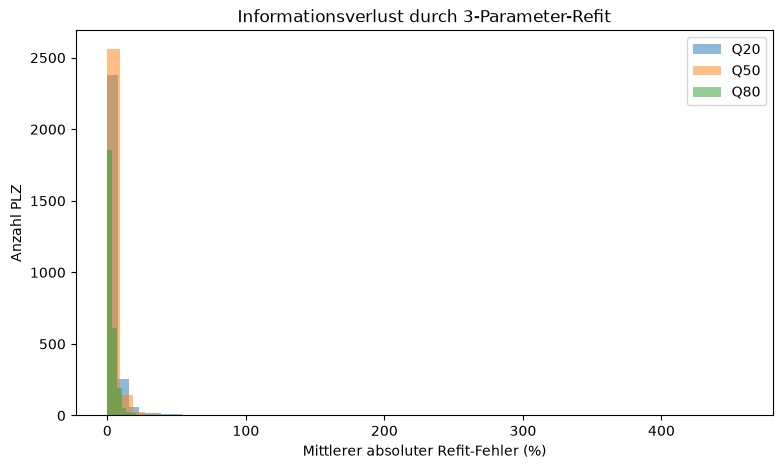

In [9]:
# Verteilung der mittleren Refit-Fehler visualisieren
plt.figure(figsize=(9, 5))
plt.hist(diag["q20_refit_mean_abs_pct"].dropna(), bins=50, alpha=0.5, label="Q20")
plt.hist(diag["q50_refit_mean_abs_pct"].dropna(), bins=50, alpha=0.5, label="Q50")
plt.hist(diag["q80_refit_mean_abs_pct"].dropna(), bins=50, alpha=0.5, label="Q80")
plt.xlabel("Mittlerer absoluter Refit-Fehler (%)")
plt.ylabel("Anzahl PLZ")
plt.title("Informationsverlust durch 3-Parameter-Refit")
plt.legend()
plt.show()


## 8. Exporte

In [10]:
params.to_csv(OUTPUT_PARAMETERS, index=False, encoding="utf-8-sig")
diag.to_csv(OUTPUT_DIAGNOSTICS, index=False, encoding="utf-8-sig")

if EXPORT_CURVES:
    curves = pd.DataFrame(curve_rows)
    curves.to_csv(OUTPUT_CURVES, index=False, encoding="utf-8-sig")

print("Exportiert:")
print(" -", OUTPUT_PARAMETERS.resolve())
print(" -", OUTPUT_DIAGNOSTICS.resolve())
if EXPORT_CURVES:
    print(" -", OUTPUT_CURVES.resolve())


Exportiert:
 - C:\Users\misch\Dropbox\Immobilien\Immo-Staitistiken-ab2025\ProjektOktober2026\mietmodell_plz_parameter.csv
 - C:\Users\misch\Dropbox\Immobilien\Immo-Staitistiken-ab2025\ProjektOktober2026\mietmodell_diagnostik.csv
 - C:\Users\misch\Dropbox\Immobilien\Immo-Staitistiken-ab2025\ProjektOktober2026\mietmodell_kurven_30_180.csv


In [11]:
import json
import numpy as np

# Zusätzlich zur CSV: kompakter, valider JSON-Export für HTML/JavaScript
json_data = {}
skipped = []

parameter_cols = [
    "q20_beta0", "q20_beta1", "q20_beta2",
    "q50_beta0", "q50_beta1", "q50_beta2",
    "q80_beta0", "q80_beta1", "q80_beta2"
]

for _, row in params.iterrows():
    plz_key = str(row["plz"]).zfill(4)

    # PLZ nur exportieren, wenn alle 9 Parameter gültige Zahlen sind
    values = row[parameter_cols].astype(float).to_numpy()

    if not np.all(np.isfinite(values)):
        skipped.append(plz_key)
        continue

    json_data[plz_key] = {
        "q20": [
            float(row["q20_beta0"]),
            float(row["q20_beta1"]),
            float(row["q20_beta2"])
        ],
        "q50": [
            float(row["q50_beta0"]),
            float(row["q50_beta1"]),
            float(row["q50_beta2"])
        ],
        "q80": [
            float(row["q80_beta0"]),
            float(row["q80_beta1"]),
            float(row["q80_beta2"])
        ]
    }

with open("mietmodell_plz_parameter.json", "w", encoding="utf-8") as f:
    json.dump(
        json_data,
        f,
        ensure_ascii=False,
        separators=(",", ":"),
        allow_nan=False
    )

print(f"Gespeichert: mietmodell_plz_parameter.json ({len(json_data)} PLZ)")
print(f"Übersprungen wegen fehlender/ungültiger Parameter: {len(skipped)} PLZ")

if skipped:
    print("Übersprungene PLZ:", ", ".join(skipped))


Gespeichert: mietmodell_plz_parameter.json (2756 PLZ)
Übersprungen wegen fehlender/ungültiger Parameter: 10 PLZ
Übersprungene PLZ: 2887, 6661, 6690, 7113, 7115, 7447, 7546, 7605, 7742, 7745


## 9. Anwendung der 9 Parameter

Mit der Parameterdatei kann der Quadratmeterpreis für eine beliebige Fläche zwischen 30 und 180 m² unmittelbar berechnet werden.


In [12]:
def estimate_from_parameters(plz, area_m2, parameter_table=params):
    if not (AREA_MIN <= area_m2 <= AREA_MAX):
        raise ValueError(f"Wohnfläche muss zwischen {AREA_MIN} und {AREA_MAX} m² liegen.")

    r = parameter_table.loc[parameter_table["plz"].astype(str) == str(plz).zfill(4)]
    if len(r) != 1:
        raise KeyError(f"PLZ {plz} nicht eindeutig in Parameterdatei gefunden.")

    r = r.iloc[0]
    x = np.array([1.0, np.log(area_m2), np.log(area_m2)**2])

    result = {}
    for label in ["q20", "q50", "q80"]:
        beta = np.array([
            r[f"{label}_beta0"],
            r[f"{label}_beta1"],
            r[f"{label}_beta2"],
        ])
        result[label] = float(x @ beta)

    return result

# Beispiel:
# estimate_from_parameters("8001", 85)


## Hinweise zur Interpretation

- Die Werte sind **Netto-Angebotsmieten** (Nebenkosten abgezogen), nicht zwingend tatsächlich abgeschlossene Vertragsmieten.
- Q20/Q50/Q80 beschreiben die bedingte Verteilung der Angebotsmiete pro m²/Jahr.
- Räumliche Glättung wird vor allem dort eingesetzt, wo im relevanten ±20-%-Flächenfenster wenige eigene Inserate vorhanden sind.
- `mietmodell_diagnostik.csv` sollte bei jeder fachlichen Anwendung mitgeführt werden. Besonders hohe Nachbargewichte, grosse Refit-Fehler oder Quantilkreuzungen sind Warnsignale.
- Die Koeffizienten sollten nicht ausserhalb von 30–180 m² extrapoliert werden.
- Wenn später Inseratedaten mit Zeitstempel verfügbar sind, sollte zusätzlich ein Zeit-/Markteffekt modelliert werden.

- Bei Inseraten ohne ausgewiesene Nebenkosten werden diese aus Wohnfläche und PLZ geschätzt; die Nettomiete ist dort entsprechend eine Modellgrösse.
